# Étape 4 – Statistiques : qu'est-ce qui influence la note client ?

**Objectif :** mesurer, avec des graphiques et des tests statistiques, quels facteurs
(délai, retard, frais de port, nombre d'articles…) sont liés à une mauvaise note.

Ce notebook lit directement les données dans la base PostgreSQL `olist` chargée par `src/etl.py`.

> 💡 Pour exécuter une cellule : clique dedans puis **Maj + Entrée**.

## 0. Préparation : librairies et connexion à la base

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine

# Permet d'importer src/config.py (qui lit le mot de passe dans .env)
sys.path.insert(0, str(Path.cwd().parent / "src"))
from config import pg_url

engine = create_engine(pg_url())

# Style des graphiques : sobre et lisible
COULEUR = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.3,
    "font.size": 11,
})

# Test de connexion
pd.read_sql("SELECT COUNT(*) AS nb_commandes FROM orders", engine)

,nb_commandes
0,99441


## 1. Comment se répartissent les notes clients ?

Avant de chercher des causes, on regarde **la forme** des données : combien d'avis à 1, 2, 3, 4 et 5 étoiles ?

In [2]:
notes = pd.read_sql("""
    SELECT review_score AS note,
           COUNT(*)     AS nb_avis
    FROM order_reviews
    GROUP BY review_score
    ORDER BY review_score
""", engine)

notes["pct"] = (100 * notes["nb_avis"] / notes["nb_avis"].sum()).round(1)
notes

,note,nb_avis,pct
0,1,11424,11.5
1,2,3151,3.2
2,3,8179,8.2
3,4,19142,19.3
4,5,57328,57.8


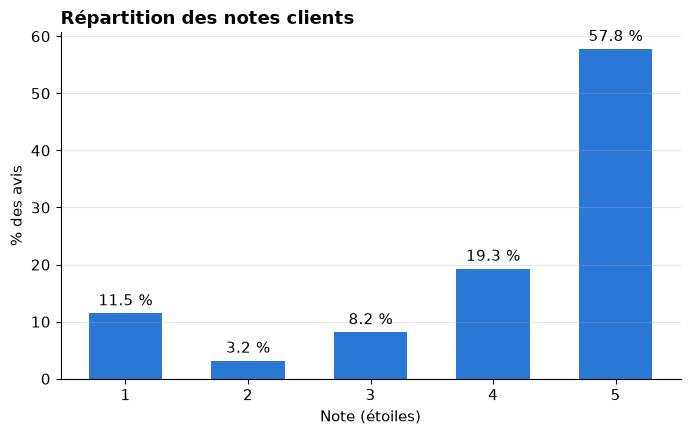

In [3]:
fig, ax = plt.subplots()
barres = ax.bar(notes["note"], notes["pct"], color=COULEUR, width=0.6)

# Valeur affichée au-dessus de chaque barre
ax.bar_label(barres, labels=[f"{p} %" for p in notes["pct"]], padding=3)

ax.set_title("Répartition des notes clients", loc="left", fontweight="bold")
ax.set_xlabel("Note (étoiles)")
ax.set_ylabel("% des avis")
ax.set_xticks([1, 2, 3, 4, 5])
plt.show()

### 🎯 À toi d'interpréter

1. Quelle note est **la plus fréquente** ? Et la **deuxième** ?
2. La forme du graphique est-elle « en cloche » (beaucoup de 3, peu de 1 et de 5) ? Sinon, à quoi ressemble-t-elle ?
3. Quel **% d'avis négatifs** (1 ou 2 étoiles) ?

✍️ *Écris ta réponse ici  :*
la plus fréquente est la 5 , puis la 4 
elle est sous forme de U entre 1 et 4 puis la 5 qui est trés haute
(11.5 + 3.2)% = 14.7%

## 2. La note dépend-elle de l'écart à la date de livraison promise ?

En SQL, on a comparé « à l'heure » contre « en retard ». Ici, on va plus loin : on mesure **de combien de jours**
chaque commande arrive **avant ou après** la date promise au client, puis on regarde la note.

**Étape 1 :** on récupère une ligne par commande livrée, avec son écart en jours et sa note.
- `delai_jours` = nombre de jours entre l'achat et la livraison
- `ecart_jours` = livraison réelle − livraison promise → **négatif = en avance**, **positif = en retard**

In [4]:
commandes = pd.read_sql("""
    WITH notes AS (
        SELECT order_id, AVG(review_score) AS note
        FROM order_reviews
        GROUP BY order_id
    )
    SELECT o.order_id,
           o.order_delivered_customer_date::date - o.order_purchase_timestamp::date      AS delai_jours,
           o.order_delivered_customer_date::date - o.order_estimated_delivery_date::date AS ecart_jours,
           n.note
    FROM orders o
    JOIN notes n ON n.order_id = o.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
""", engine)

print(f"{len(commandes):,} commandes livrées avec une note".replace(",", " "))
commandes.head()

95 824 commandes livrées avec une note


,order_id,delai_jours,ecart_jours,note
0,5f07fda0de6271f38a81a1dd718c7a82,15,-17,3.0
1,738c536e3bfc3c99dddffed112e89349,4,-8,5.0
2,c0b4d042df532a3a84b95e89bf2a53c1,17,-10,4.0
3,c8bc8f1025acaa48d5be4ea4c11c88a3,4,-18,5.0
4,8d40f6aeb11aa6d03d17b3fa59b14fbe,12,-9,2.0


**Étape 2 : les statistiques descriptives.** `describe()` résume chaque colonne en une ligne :
moyenne (`mean`), écart-type (`std`), minimum, quartiles (25 %, 50 % = médiane, 75 %) et maximum.

In [5]:
commandes[["delai_jours", "ecart_jours", "note"]].describe().round(1)

,delai_jours,ecart_jours,note
count,95824.0,95824.0,95824.0
mean,12.5,-11.9,4.2
std,9.5,10.1,1.3
min,0.0,-147.0,1.0
25%,7.0,-17.0,4.0
50%,10.0,-12.0,5.0
75%,16.0,-7.0,5.0
max,208.0,188.0,5.0


**Étape 3 : on range les commandes dans des « tranches » d'écart** avec `pd.cut`,
puis on calcule pour chaque tranche le nombre de commandes, la note moyenne et le % d'avis négatifs.

In [6]:
bornes = [float("-inf"), -11, -6, 0, 5, 10, float("inf")]
tranches = ["> 10 j en avance", "6-10 j en avance", "0-5 j en avance",
            "1-5 j de retard", "6-10 j de retard", "> 10 j de retard"]

commandes["tranche"] = pd.cut(commandes["ecart_jours"], bins=bornes, labels=tranches)

par_tranche = (commandes
               .groupby("tranche", observed=True)
               .agg(nb_commandes=("note", "size"),
                    note_moyenne=("note", "mean"),
                    pct_negatifs=("note", lambda s: 100 * (s <= 2).mean()))
               .round(2))
par_tranche

,nb_commandes,note_moyenne,pct_negatifs
tranche,,,
> 10 j en avance,56905,4.32,8.92
6-10 j en avance,22442,4.28,9.13
0-5 j en avance,10096,4.14,11.19
1-5 j de retard,2722,2.99,41.15
6-10 j de retard,1634,1.77,77.36
> 10 j de retard,2025,1.71,78.77


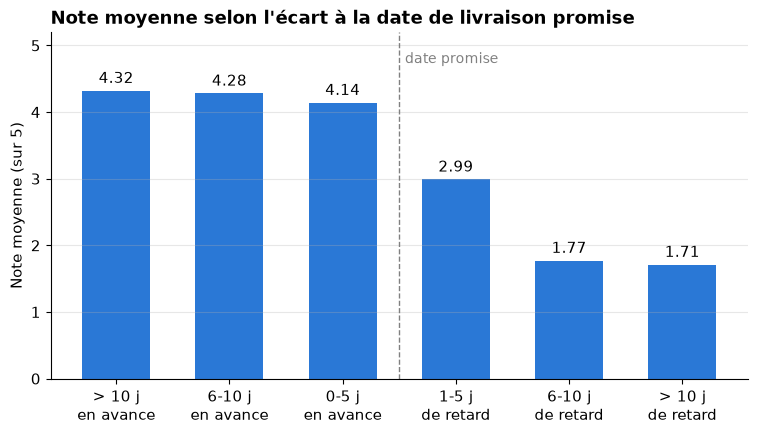

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
barres = ax.bar(range(len(par_tranche)), par_tranche["note_moyenne"], color=COULEUR, width=0.6)
ax.bar_label(barres, labels=[f"{v:.2f}" for v in par_tranche["note_moyenne"]], padding=3)

# Ligne de séparation entre « en avance / à l'heure » et « en retard »
ax.axvline(2.5, color="gray", linestyle="--", linewidth=1)
ax.text(2.55, 4.9, "date promise", color="gray", fontsize=10, va="top")

etiquettes = [t.replace(" en ", "\nen ").replace(" de ", "\nde ") for t in par_tranche.index]
ax.set_xticks(range(len(par_tranche)), etiquettes)
ax.set_ylim(0, 5.2)
ax.set_title("Note moyenne selon l'écart à la date de livraison promise", loc="left", fontweight="bold")
ax.set_ylabel("Note moyenne (sur 5)")
plt.show()

### 🎯 À toi d'interpréter

1. Que se passe-t-il pour la note **dès que la date promise est dépassée** ?
2. Être livré **très en avance** (plus de 10 jours) améliore-t-il beaucoup la note par rapport à 0-5 jours d'avance ?
3. Pour les commandes **plus de 10 jours en retard**, quel est le **% d'avis négatifs** ? Compare-le aux 14,7 % de la moyenne générale.
4. 💼 **Question business :** si tu étais manager chez Olist, quelle **décision** prendrais-tu sur la façon d'afficher la date de livraison promise ?

✍️ *Écris tes réponses ici :*

1. La note chute de 4,14 à 2,99 dès que la date promise est dépassée, puis tombe à ~1,7 au-delà de 6 jours de retard.
2. Livrer très en avance n'apporte presque rien (+0,18 point) : l'effet est asymétrique.
3. Au-delà de 10 jours de retard, 78,8 % d'avis négatifs, contre 14,7 % en moyenne (plus de 5 fois plus).
4. Recommandation : garder des dates promises prudentes (surtout pour les États éloignés) et prévenir le client en cas de risque de retard.

## 3. Le test du khi-deux : l'effet du retard est-il dû au hasard ?

Un graphique **montre** une différence ; un test statistique dit si elle est **fiable**.

Le **test du khi-deux (χ²)** compare deux variables **catégorielles** (oui / non) :
- *la commande est-elle en retard ?* (oui / non)
- *l'avis est-il négatif (1-2 étoiles) ?* (oui / non)

Il calcule la **p-value** : la probabilité d'observer un tel écart **si le retard n'avait aucun effet**.
- **p < 0,05** → l'écart est **statistiquement significatif** (pas dû au hasard)
- **p ≥ 0,05** → on ne peut pas conclure

**Étape 1 :** le tableau croisé (« table de contingence ») avec `pd.crosstab`.

In [8]:
from scipy.stats import chi2_contingency

commandes["en_retard"] = commandes["ecart_jours"] > 0
commandes["avis_negatif"] = commandes["note"] <= 2

tableau = pd.crosstab(commandes["en_retard"], commandes["avis_negatif"])
tableau.index = ["À l'heure", "En retard"]
tableau.columns = ["Avis positif / neutre", "Avis négatif"]
tableau

,Avis positif / neutre,Avis négatif
À l'heure,81186,8257
En retard,2402,3979


**Étape 2 :** le test, puis l'affichage du % d'avis négatifs dans chaque groupe.

In [9]:
chi2, p_value, ddl, attendu = chi2_contingency(tableau)

pct_negatifs = (100 * tableau["Avis négatif"] / tableau.sum(axis=1)).round(1)
print(pct_negatifs.to_string(), "\n")
print(f"Khi-deux = {chi2:,.0f}")
print(f"p-value  = {p_value:.2e}" if p_value > 0 else "p-value  < 1e-300 (quasiment zéro)")
print("=> Écart SIGNIFICATIF" if p_value < 0.05 else "=> Écart NON significatif")

À l'heure     9.2
En retard    62.4 

Khi-deux = 15,087
p-value  < 1e-300 (quasiment zéro)
=> Écart SIGNIFICATIF


> 💡 **Lire une p-value en notation scientifique :** `1.2e-05` = 0,000012.
> Un très grand exposant négatif (ex. `e-300`) veut dire « quasiment impossible que ce soit le hasard ».

**Étape 3 :** on refait le test de l'**analyse SQL n°6** (la 1re commande en retard fait-elle moins revenir le client ?),
cette fois avec les **chiffres exacts** et non des pourcentages arrondis.

In [10]:
fidelite = pd.read_sql("""
    WITH cmd AS (
        SELECT c.customer_unique_id,
               o.order_delivered_customer_date::date > o.order_estimated_delivery_date::date AS en_retard,
               ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id ORDER BY o.order_purchase_timestamp) AS rang,
               COUNT(*)     OVER (PARTITION BY c.customer_unique_id) AS nb_commandes
        FROM orders o
        JOIN customers c ON c.customer_id = o.customer_id
        WHERE o.order_status NOT IN ('canceled', 'unavailable')
    )
    SELECT CASE WHEN en_retard THEN 'En retard' ELSE 'À l''heure' END AS premiere_commande,
           SUM(CASE WHEN nb_commandes > 1 THEN 1 ELSE 0 END)          AS revenus,
           SUM(CASE WHEN nb_commandes = 1 THEN 1 ELSE 0 END)          AS pas_revenus
    FROM cmd
    WHERE rang = 1 AND en_retard IS NOT NULL
    GROUP BY 1
    ORDER BY 1
""", engine).set_index("premiere_commande")

chi2_f, p_f, _, _ = chi2_contingency(fidelite)
fidelite["pct_revenus"] = (100 * fidelite["revenus"] / fidelite.sum(axis=1)).round(2)
print(fidelite.to_string(), "\n")
print(f"p-value = {p_f:.4f}", "=> SIGNIFICATIF" if p_f < 0.05 else "=> NON significatif")

                   revenus  pas_revenus  pct_revenus
premiere_commande                                   
À l'heure             2665        84281         3.07
En retard              160         6187         2.52 

p-value = 0.0162 => SIGNIFICATIF


## 4. Quels autres facteurs sont liés à la note ? La corrélation

La **corrélation** mesure si deux variables **numériques** évoluent ensemble. Elle va de **−1 à +1** :
- **proche de +1** : quand l'une monte, l'autre monte aussi
- **proche de −1** : quand l'une monte, l'autre baisse
- **proche de 0** : pas de lien (en ligne droite)

Repère courant : |r| < 0,1 → lien négligeable · 0,1-0,3 → faible · 0,3-0,5 → modéré · > 0,5 → fort.

On utilise la corrélation de **Spearman** (et non de Pearson) car la note est une **échelle de 1 à 5**
et nos variables contiennent des **valeurs extrêmes** : Spearman travaille sur les **rangs**, il est plus robuste.

**Étape 1 :** on construit, pour chaque commande, plusieurs caractéristiques (« features ») candidates.

In [11]:
facteurs = pd.read_sql("""
    WITH notes AS (
        SELECT order_id, AVG(review_score) AS note
        FROM order_reviews
        GROUP BY order_id
    ),
    articles AS (
        SELECT order_id,
               COUNT(*)                  AS nb_articles,
               COUNT(DISTINCT seller_id) AS nb_vendeurs,
               SUM(price)                AS prix_total,
               SUM(freight_value)        AS frais_port
        FROM order_items
        GROUP BY order_id
    )
    SELECT o.order_id,
           o.order_delivered_customer_date::date - o.order_purchase_timestamp::date      AS delai_jours,
           o.order_delivered_customer_date::date - o.order_estimated_delivery_date::date AS ecart_jours,
           o.order_estimated_delivery_date::date - o.order_purchase_timestamp::date      AS delai_promis_jours,
           a.nb_articles, a.nb_vendeurs, a.prix_total, a.frais_port,
           n.note
    FROM orders o
    JOIN notes    n ON n.order_id = o.order_id
    JOIN articles a ON a.order_id = o.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
""", engine)

# Part des frais de port dans le prix (en %) : 20 R$ de port n'a pas le même poids sur 30 R$ que sur 1 000 R$
facteurs["frais_port_pct"] = 100 * facteurs["frais_port"] / facteurs["prix_total"]
facteurs.describe().round(1)

,delai_jours,ecart_jours,delai_promis_jours,nb_articles,nb_vendeurs,prix_total,frais_port,note,frais_port_pct
count,95824.0,95824.0,95824.0,95824.0,95824.0,95824.0,95824.0,95824.0,95824.0
mean,12.5,-11.9,24.4,1.1,1.0,136.8,22.8,4.2,30.8
std,9.5,10.1,8.8,0.5,0.1,207.8,21.5,1.3,31.2
min,0.0,-147.0,3.0,1.0,1.0,0.8,0.0,1.0,0.0
25%,7.0,-17.0,19.0,1.0,1.0,45.9,13.8,4.0,13.2
50%,10.0,-12.0,24.0,1.0,1.0,86.2,17.2,5.0,22.4
75%,16.0,-7.0,29.0,1.0,1.0,149.9,24.0,5.0,38.1
max,208.0,188.0,156.0,21.0,5.0,13440.0,1795.0,5.0,2144.7


**Étape 2 :** la corrélation de chaque facteur avec la note, triée du plus négatif au plus positif.

In [12]:
correlations = (facteurs
                .drop(columns=["order_id"])
                .corr(method="spearman")["note"]
                .drop("note")
                .sort_values())
correlations.round(3)

delai_jours          -0.235
ecart_jours          -0.176
nb_articles          -0.108
nb_vendeurs          -0.095
frais_port           -0.089
delai_promis_jours   -0.056
frais_port_pct       -0.031
prix_total           -0.029
Name: note, dtype: float64

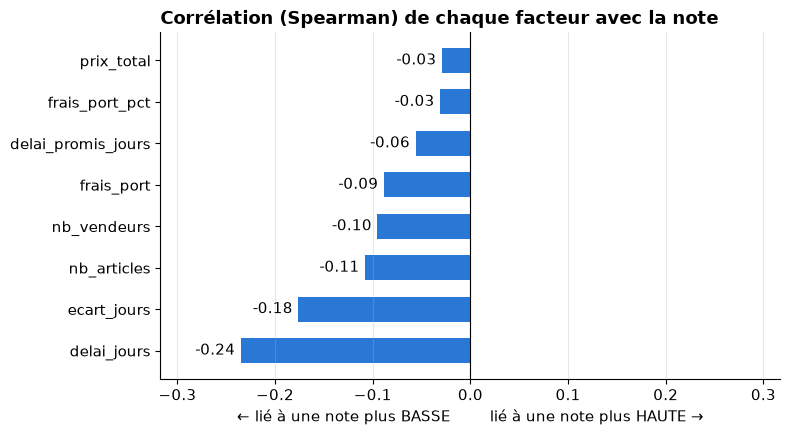

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
barres = ax.barh(correlations.index, correlations.values, color=COULEUR, height=0.6)
ax.bar_label(barres, labels=[f"{v:+.2f}" for v in correlations.values], padding=4)

ax.axvline(0, color="black", linewidth=0.8)
limite = max(0.1, correlations.abs().max() * 1.35)
ax.set_xlim(-limite, limite)
ax.grid(axis="x", alpha=0.3)
ax.grid(axis="y", visible=False)
ax.set_title("Corrélation (Spearman) de chaque facteur avec la note", loc="left", fontweight="bold")
ax.set_xlabel("← lié à une note plus BASSE        lié à une note plus HAUTE →")
plt.show()

### 🎯 À toi d'interpréter

1. Le khi-deux de l'étape 3.2 : le retard est-il **significativement** lié aux avis négatifs ? Quel % d'avis négatifs dans chaque groupe ?
2. Le test de **fidélité** avec les chiffres exacts : la p-value confirme-t-elle notre conclusion SQL (p ≈ 0,015) ?
3. Quel facteur a la corrélation **la plus forte** (en valeur absolue) avec la note ? Est-ce un lien faible, modéré ou fort ?
4. Le **prix** et les **frais de port** jouent-ils beaucoup sur la note ?
5. Regarde `nb_vendeurs` : pourquoi une commande avec **plusieurs vendeurs** pourrait-elle être moins bien notée ? (Indice : pense aux colis 📦)
6. ⚠️ Corrélation ≠ causalité : donne un exemple de raison **cachée** qui pourrait expliquer à la fois un long délai et une mauvaise note.

✍️ *Écris tes réponses ici :*

La livraison domine la satisfaction : un retard multiplie les avis négatifs par 7 (9 % → 62 %, khi-deux p ≈ 0). L’effet est un seuil : l’avance rapporte peu, le retard coûte cher. Le prix et les frais de port n’ont quasiment aucun lien avec la note. Les commandes à plusieurs articles ou vendeurs sont un peu moins bien notées. 